# Phase 3: Comprehensive Hyperparameter Tuning & Model Optimization
## Configuration: 3-Tier Clinically Actionable CAD Care Staging
### Evaluated Architectures: Logistic Regression, KNN, SVM, Random Forest, Lightweight Neural Network

### Executive Objective:
In this phase, we perform exhaustive hyperparameter optimization across **all 5 machine learning architectures** using 5-Fold Stratified Cross-Validation (`scoring='f1_weighted'`).

### Parameter Search Space Design:
We evaluate an extensive grid of hyperparameters across all models, intentionally including parameters across wide ranges (even those anticipated to yield lower performance) to empirically map the full objective landscape:
1. **Logistic Regression**: Regularization strength ($C \in [0.001, 50.0]$), solvers (`lbfgs`, `newton-cg`, `saga`), and class weighting strategies (`None`, `'balanced'`).
2. **K-Nearest Neighbors (KNN)**: Neighbor counts ($k \in [3, 21]$), distance weighting functions (`uniform`, `distance`), and distance metrics (`euclidean`, `manhattan`, `minkowski`).
3. **Support Vector Machine (SVM)**: Penalty parameter ($C \in [0.01, 50.0]$), diverse kernel functions (`rbf`, `linear`, `poly`, `sigmoid`), gamma scaling (`scale`, `auto`, numeric), and class weights.
4. **Random Forest Classifier**: Tree counts ($n \in [50, 200]$), splitting impurity criteria (`gini`, `entropy`), maximum tree depths ($4, 8, 12, \text{None}$), minimum sample split/leaf thresholds, and class weights.
5. **Lightweight Neural Network (MLP)**: Single and multi-layer topologies (1 to 3 hidden layers), non-linear activations (`relu`, `tanh`), L2 penalty parameters ($lpha$), initial learning rates, and optimization solvers (`adam`, `sgd`).

In [1]:
import os
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.preprocessing import MinMaxScaler, label_binarize
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, classification_report, confusion_matrix, roc_curve, auc
)

# Styling
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['figure.dpi'] = 110

print("[OK] Tuning environment initialized successfully.")

[OK] Tuning environment initialized successfully.


In [2]:
candidates = [
    os.path.join('..', 'datasets', 'heart+disease', 'processed.cleveland.data'),
    os.path.join('datasets', 'heart+disease', 'processed.cleveland.data'),
    'processed.cleveland.data'
]
data_path = next((p for p in candidates if os.path.exists(p)), None)
if data_path is None:
    raise FileNotFoundError("Could not locate 'processed.cleveland.data'.")

COLUMNS = [
    'age', 'sex', 'cp', 'trestbps', 'chol', 'fbs',
    'restecg', 'thalach', 'exang', 'oldpeak', 'slope',
    'ca', 'thal', 'target'
]

df_raw = pd.read_csv(data_path, names=COLUMNS, na_values='?')

def map_to_3tier(val):
    if val == 0:
        return 0
    elif val in [1, 2]:
        return 1
    else:
        return 2

df_raw['target_processed'] = df_raw['target'].apply(map_to_3tier)
class_names = ['Tier 0: No CAD', 'Tier 1: Mild/Mod CAD', 'Tier 2: Severe/Crit CAD']
classes_list = [0, 1, 2]

# Train-Test Split (80/20 Stratified)
X = df_raw.drop(columns=['target', 'target_processed']).copy()
y = df_raw['target_processed'].copy()

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=42
)

# Imputation fit strictly on X_train
ca_median = X_train['ca'].median()
thal_mode = X_train['thal'].mode()[0]
X_train['ca'] = X_train['ca'].fillna(ca_median)
X_test['ca'] = X_test['ca'].fillna(ca_median)
X_train['thal'] = X_train['thal'].fillna(thal_mode)
X_test['thal'] = X_test['thal'].fillna(thal_mode)

# One-Hot Encoding
nominal_cols = ['cp', 'restecg', 'slope', 'thal']
X_train_ohe = pd.get_dummies(X_train, columns=nominal_cols, drop_first=False)
X_test_ohe = pd.get_dummies(X_test, columns=nominal_cols, drop_first=False)
X_train_ohe, X_test_ohe = X_train_ohe.align(X_test_ohe, join='left', axis=1, fill_value=0)

# MinMax Scaling
cont_cols = ['age', 'trestbps', 'chol', 'thalach', 'oldpeak', 'ca']
scaler = MinMaxScaler()
X_train_scaled = X_train_ohe.copy()
X_test_scaled = X_test_ohe.copy()
X_train_scaled[cont_cols] = scaler.fit_transform(X_train_ohe[cont_cols])
X_test_scaled[cont_cols] = scaler.transform(X_test_ohe[cont_cols])

X_train_final, y_train_final = X_train_scaled, y_train
print(f"[OK] Training fold prepared authentically: {len(y_train_final)} instances.")

[OK] Training fold prepared authentically: 242 instances.


### 1. Baseline Performance Reference (Before Tuning)
We compute default baseline scores on the holdout test set to establish exact performance benchmarks for all 5 architectures.

In [3]:
baseline_models = {
    'Logistic Regression': LogisticRegression(max_iter=2000, random_state=42),
    'K-Nearest Neighbors': KNeighborsClassifier(n_neighbors=5),
    'Support Vector Machine': SVC(probability=True, random_state=42),
    'Random Forest': RandomForestClassifier(n_estimators=100, random_state=42),
    'Neural Network (LNN)': MLPClassifier(hidden_layer_sizes=(64, 32), max_iter=1000, random_state=42)
}

y_test_bin = label_binarize(y_test, classes=classes_list)

baseline_records = []
for name, m in baseline_models.items():
    m.fit(X_train_final, y_train_final)
    yp = m.predict(X_test_scaled)
    yprob = m.predict_proba(X_test_scaled)
    
    baseline_records.append({
        'Model': name,
        'Accuracy': accuracy_score(y_test, yp),
        'Precision (Weighted)': precision_score(y_test, yp, average='weighted', zero_division=0),
        'Recall (Weighted)': recall_score(y_test, yp, average='weighted', zero_division=0),
        'F1-Score (Weighted)': f1_score(y_test, yp, average='weighted', zero_division=0),
        'ROC-AUC (Macro OVR)': roc_auc_score(y_test_bin, yprob, multi_class='ovr', average='macro')
    })

df_baseline_ref = pd.DataFrame(baseline_records)
print("=== BASELINE PERFORMANCE BENCHMARK (TEST SET) ===")
print(df_baseline_ref.to_string(index=False))

=== BASELINE PERFORMANCE BENCHMARK (TEST SET) ===
                 Model  Accuracy  Precision (Weighted)  Recall (Weighted)  F1-Score (Weighted)  ROC-AUC (Macro OVR)
   Logistic Regression  0.704918              0.707329           0.704918             0.696183             0.836445
   K-Nearest Neighbors  0.622951              0.588212           0.622951             0.598670             0.775881
Support Vector Machine  0.688525              0.653005           0.688525             0.657936             0.819201
         Random Forest  0.688525              0.650641           0.688525             0.663050             0.822046
  Neural Network (LNN)  0.655738              0.649523           0.655738             0.652338             0.775457


### 2. Systematic Hyperparameter Tuning via GridSearchCV
We construct comprehensive parameter grids for all 5 models and optimize using 5-Fold Stratified Cross-Validation (`scoring='f1_weighted'`).

In [ ]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

param_grids = {
    'Logistic Regression': {
        'estimator': LogisticRegression(max_iter=2500, random_state=42),
        'params': {
            'C': [0.001, 0.01, 0.1, 1.0, 10.0, 50.0],
            'solver': ['lbfgs', 'newton-cg', 'saga'],
            'class_weight': [None, 'balanced']
        }
    },
    'K-Nearest Neighbors': {
        'estimator': KNeighborsClassifier(),
        'params': {
            'n_neighbors': [3, 5, 7, 9, 11, 15, 21],
            'weights': ['uniform', 'distance'],
            'metric': ['euclidean', 'manhattan', 'minkowski'],
            'p': [1, 2]
        }
    },
    'Support Vector Machine': {
        'estimator': SVC(probability=True, random_state=42),
        'params': {
            'C': [0.01, 0.1, 1.0, 5.0, 10.0, 50.0],
            'kernel': ['rbf', 'linear', 'poly', 'sigmoid'],
            'gamma': ['scale', 'auto', 0.01, 0.1],
            'class_weight': [None, 'balanced']
        }
    },
    'Random Forest': {
        'estimator': RandomForestClassifier(random_state=42),
        'params': {
            'n_estimators': [50, 100, 200],
            'criterion': ['gini', 'entropy'],                      
            'max_depth': [4, 8, 12, None],
            'min_samples_split': [2, 5, 10],
            'min_samples_leaf': [1, 2, 4],
            'class_weight': [None, 'balanced']
        }
    },
    'Neural Network (LNN)': {
        'estimator': MLPClassifier(max_iter=1000, early_stopping=True, n_iter_no_change=15, random_state=42),
        'params': {
            'hidden_layer_sizes': [(32,), (64, 32), (128, 64), (64, 32, 16)],
            'activation': ['relu', 'tanh'],
            'alpha': [0.0001, 0.001, 0.01],
            'learning_rate_init': [0.001, 0.01],
            'solver': ['adam', 'sgd']
        }
    }
}

tuned_models = {}
tuning_summary_records = []

for name, cfg in param_grids.items():
    print(f"Executing GridSearchCV for: {name}...")
    gs = GridSearchCV(
        estimator=cfg['estimator'],
        param_grid=cfg['params'],
        scoring='f1_weighted',
        cv=cv,
        n_jobs=-1,
        verbose=0
    )
    gs.fit(X_train_final, y_train_final)
    tuned_models[name] = gs.best_estimator_
    
    tuning_summary_records.append({
        'Model': name,
        'Best CV Score (f1_weighted)': gs.best_score_,
        'Optimal Hyperparameters': str(gs.best_params_)
    })

df_tuning_summary = pd.DataFrame(tuning_summary_records)
print("\n=== GRID SEARCH CV OPTIMIZATION SUMMARY ===")
print(df_tuning_summary.to_string(index=False))

Executing GridSearchCV for: Logistic Regression...
Executing GridSearchCV for: K-Nearest Neighbors...
Executing GridSearchCV for: Support Vector Machine...
Executing GridSearchCV for: Random Forest...
Executing GridSearchCV for: Neural Network (LNN)...

=== GRID SEARCH CV OPTIMIZATION SUMMARY ===
                 Model  Best CV Score (f1_weighted)                                                                                                           Optimal Hyperparameters
   Logistic Regression                     0.672844                                                                              {'C': 10.0, 'class_weight': None, 'solver': 'lbfgs'}
   K-Nearest Neighbors                     0.674034                                                         {'metric': 'manhattan', 'n_neighbors': 21, 'p': 1, 'weights': 'distance'}
Support Vector Machine                     0.691511                                                              {'C': 50.0, 'class_weight': None, 'gamma': 

### 3. Holdout Test Set Evaluation (All 5 Tuned Architectures)
We evaluate the 5 tuned models on the completely untouched test split ($N=61$).

In [5]:
tuned_records = []
tuned_preds = {}
tuned_probs = {}

for name, model in tuned_models.items():
    yp = model.predict(X_test_scaled)
    yprob = model.predict_proba(X_test_scaled)
    
    tuned_preds[name] = yp
    tuned_probs[name] = yprob
    
    acc = accuracy_score(y_test, yp)
    prec = precision_score(y_test, yp, average='weighted', zero_division=0)
    rec = recall_score(y_test, yp, average='weighted', zero_division=0)
    f1 = f1_score(y_test, yp, average='weighted', zero_division=0)
    auc_score = roc_auc_score(y_test_bin, yprob, multi_class='ovr', average='macro')
    
    tuned_records.append({
        'Model': name,
        'Accuracy': acc,
        'Precision (Weighted)': prec,
        'Recall (Weighted)': rec,
        'F1-Score (Weighted)': f1,
        'ROC-AUC (Macro OVR)': auc_score
    })

df_tuned_results = pd.DataFrame(tuned_records)
print("=== TUNED MODELS EVALUATION ON UNTOUCHED TEST SET (N=61) ===")
print(df_tuned_results.to_string(index=False))

=== TUNED MODELS EVALUATION ON UNTOUCHED TEST SET (N=61) ===
                 Model  Accuracy  Precision (Weighted)  Recall (Weighted)  F1-Score (Weighted)  ROC-AUC (Macro OVR)
   Logistic Regression  0.688525              0.691418           0.688525             0.680034             0.816827
   K-Nearest Neighbors  0.622951              0.549062           0.622951             0.583002             0.786602
Support Vector Machine  0.672131              0.662295           0.672131             0.665917             0.830775
         Random Forest  0.704918              0.688093           0.704918             0.691400             0.834561
  Neural Network (LNN)  0.655738              0.591433           0.655738             0.611680             0.822695


### 4. Baseline vs. Tuned Performance Delta Analysis

In [6]:
df_delta = df_tuned_results.copy()
for col in ['Accuracy', 'Precision (Weighted)', 'Recall (Weighted)', 'F1-Score (Weighted)', 'ROC-AUC (Macro OVR)']:
    df_delta[col + ' (Base)'] = df_baseline_ref[col]
    df_delta[col + ' (Delta)'] = df_tuned_results[col] - df_baseline_ref[col]

delta_cols = ['Model', 'Accuracy (Base)', 'Accuracy', 'Accuracy (Delta)',
              'F1-Score (Weighted) (Base)', 'F1-Score (Weighted)', 'F1-Score (Weighted) (Delta)',
              'ROC-AUC (Macro OVR) (Base)', 'ROC-AUC (Macro OVR)', 'ROC-AUC (Macro OVR) (Delta)']
print("=== BASELINE VS. TUNED PERFORMANCE DELTAS ===")
print(df_delta[delta_cols].to_string(index=False))

=== BASELINE VS. TUNED PERFORMANCE DELTAS ===
                 Model  Accuracy (Base)  Accuracy  Accuracy (Delta)  F1-Score (Weighted) (Base)  F1-Score (Weighted)  F1-Score (Weighted) (Delta)  ROC-AUC (Macro OVR) (Base)  ROC-AUC (Macro OVR)  ROC-AUC (Macro OVR) (Delta)
   Logistic Regression         0.704918  0.688525         -0.016393                    0.696183             0.680034                    -0.016149                    0.836445             0.816827                    -0.019618
   K-Nearest Neighbors         0.622951  0.622951          0.000000                    0.598670             0.583002                    -0.015668                    0.775881             0.786602                     0.010721
Support Vector Machine         0.688525  0.672131         -0.016393                    0.657936             0.665917                     0.007980                    0.819201             0.830775                     0.011574
         Random Forest         0.688525  0.704918         

### 5. Detailed Classification Reports (All 5 Tuned Models)

In [7]:
for name, pred in tuned_preds.items():
    print(f"\n=======================================================")
    print(f"CLASSIFICATION REPORT: {name}")
    print(f"=======================================================")
    print(classification_report(y_test, pred, target_names=class_names, zero_division=0))


CLASSIFICATION REPORT: Logistic Regression
                         precision    recall  f1-score   support

         Tier 0: No CAD       0.82      0.85      0.84        33
   Tier 1: Mild/Mod CAD       0.50      0.61      0.55        18
Tier 2: Severe/Crit CAD       0.60      0.30      0.40        10

               accuracy                           0.69        61
              macro avg       0.64      0.59      0.60        61
           weighted avg       0.69      0.69      0.68        61


CLASSIFICATION REPORT: K-Nearest Neighbors
                         precision    recall  f1-score   support

         Tier 0: No CAD       0.78      0.85      0.81        33
   Tier 1: Mild/Mod CAD       0.43      0.56      0.49        18
Tier 2: Severe/Crit CAD       0.00      0.00      0.00        10

               accuracy                           0.62        61
              macro avg       0.40      0.47      0.43        61
           weighted avg       0.55      0.62      0.58        

### 6. Master Diagnostic Dashboard: Visual Comparison Across All 5 Tuned Architectures

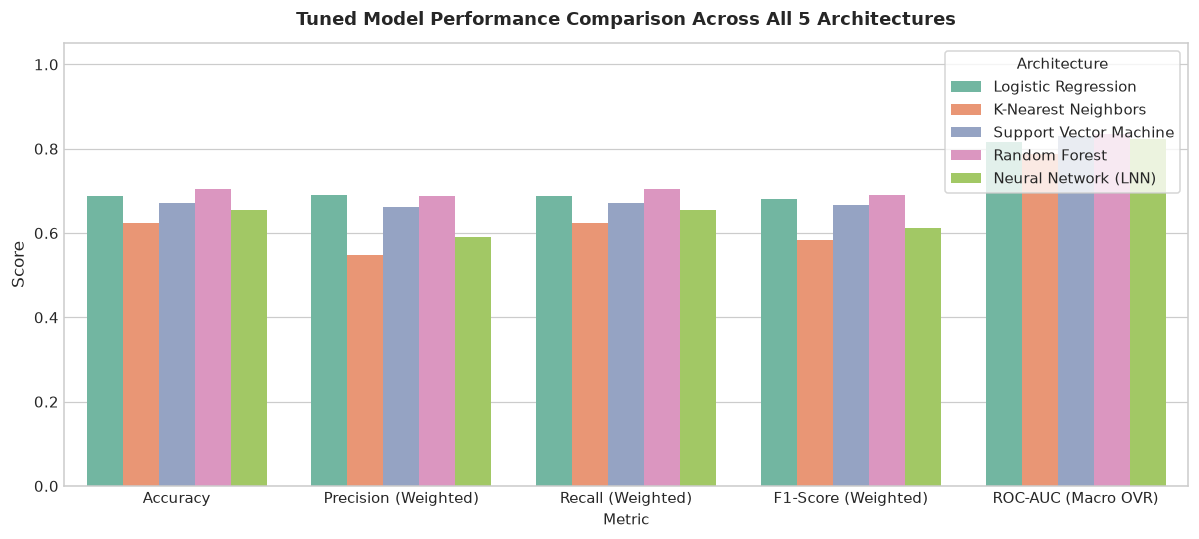

In [8]:
fig, ax = plt.subplots(figsize=(11, 5))
metrics_plot = ['Accuracy', 'Precision (Weighted)', 'Recall (Weighted)', 'F1-Score (Weighted)', 'ROC-AUC (Macro OVR)']
df_plot = df_tuned_results.melt(id_vars='Model', value_vars=metrics_plot, var_name='Metric', value_name='Score')

sns.barplot(x='Metric', y='Score', hue='Model', data=df_plot, palette='Set2', ax=ax)
ax.set_title('Tuned Model Performance Comparison Across All 5 Architectures', fontsize=12, fontweight='bold', pad=12)
ax.set_ylim(0, 1.05)
ax.set_ylabel('Score', fontsize=11)
ax.legend(title='Architecture', loc='upper right', frameon=True)
plt.tight_layout()
plt.show()

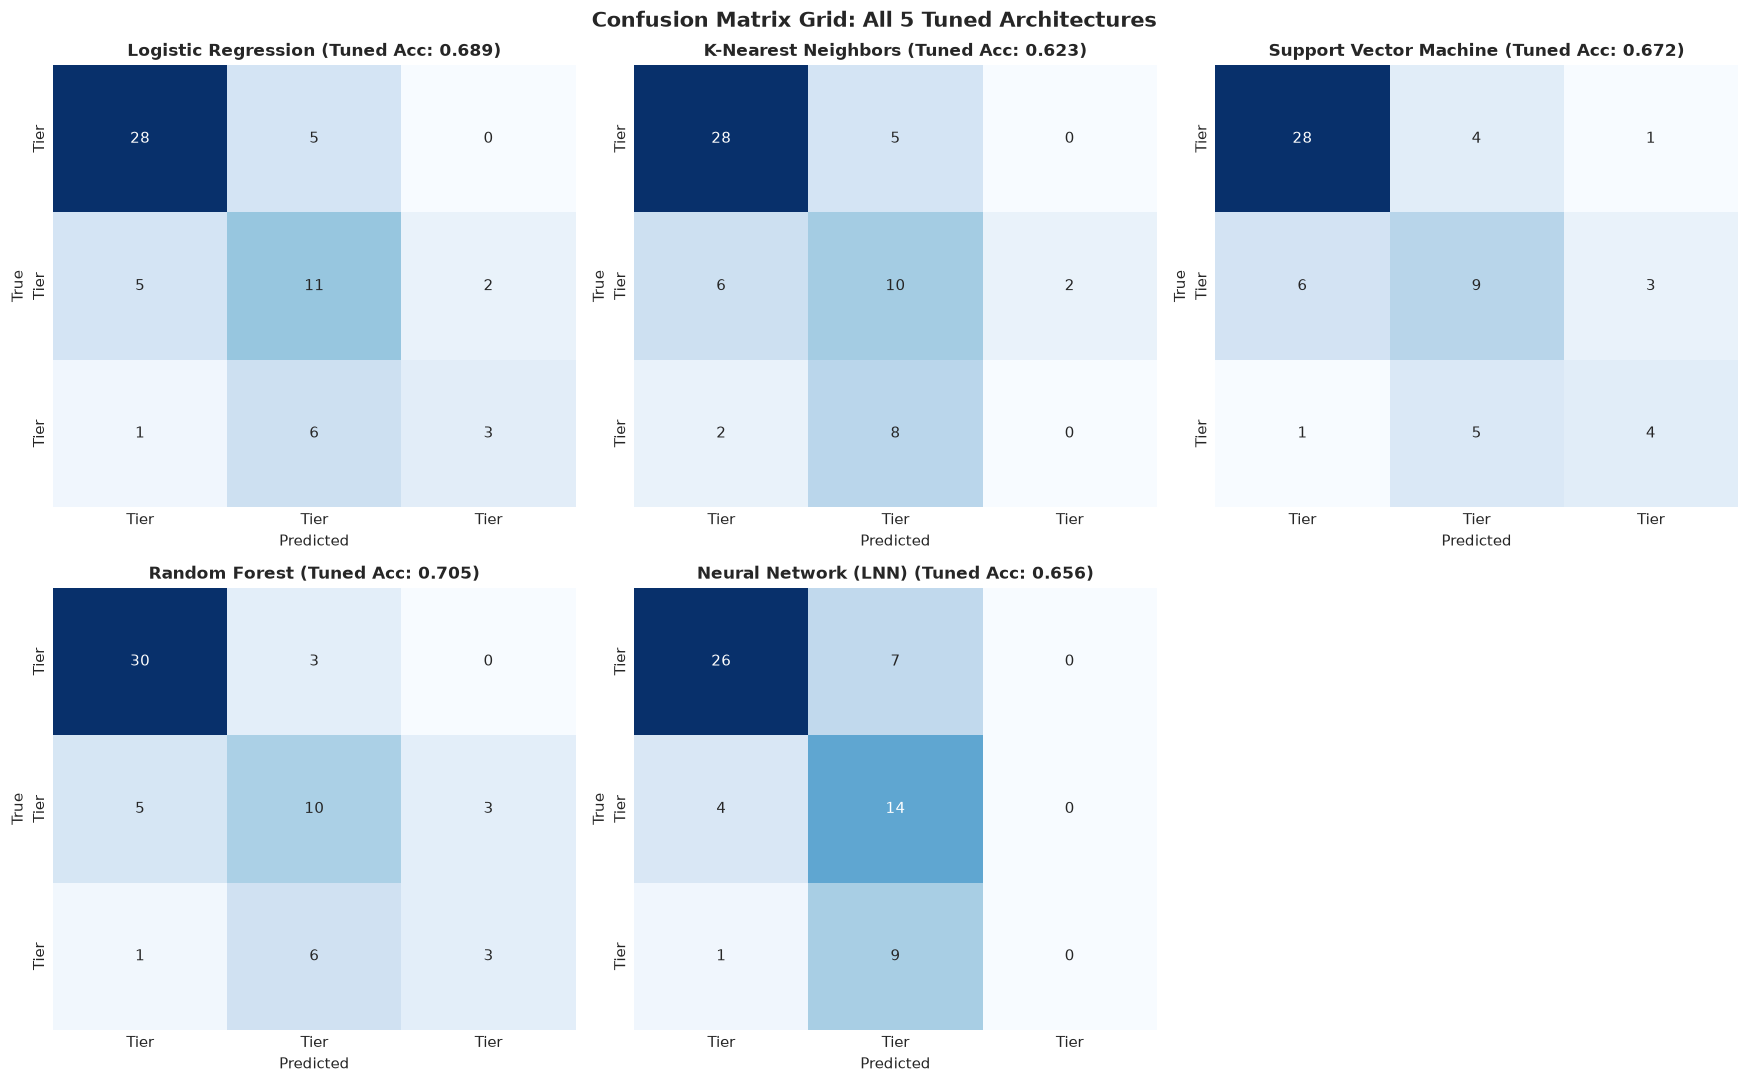

In [9]:
fig, axes = plt.subplots(2, 3, figsize=(16, 10))
axes = axes.flatten()

for idx, (name, pred) in enumerate(tuned_preds.items()):
    cm = confusion_matrix(y_test, pred)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False, ax=axes[idx],
                xticklabels=[c.split(' ')[0] for c in class_names],
                yticklabels=[c.split(' ')[0] for c in class_names])
    acc_val = df_tuned_results.loc[df_tuned_results['Model'] == name, 'Accuracy'].values[0]
    axes[idx].set_title(f'{name} (Tuned Acc: {acc_val:.3f})', fontweight='bold', fontsize=11)
    axes[idx].set_xlabel('Predicted')
    axes[idx].set_ylabel('True')

axes[5].axis('off')
plt.suptitle('Confusion Matrix Grid: All 5 Tuned Architectures', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

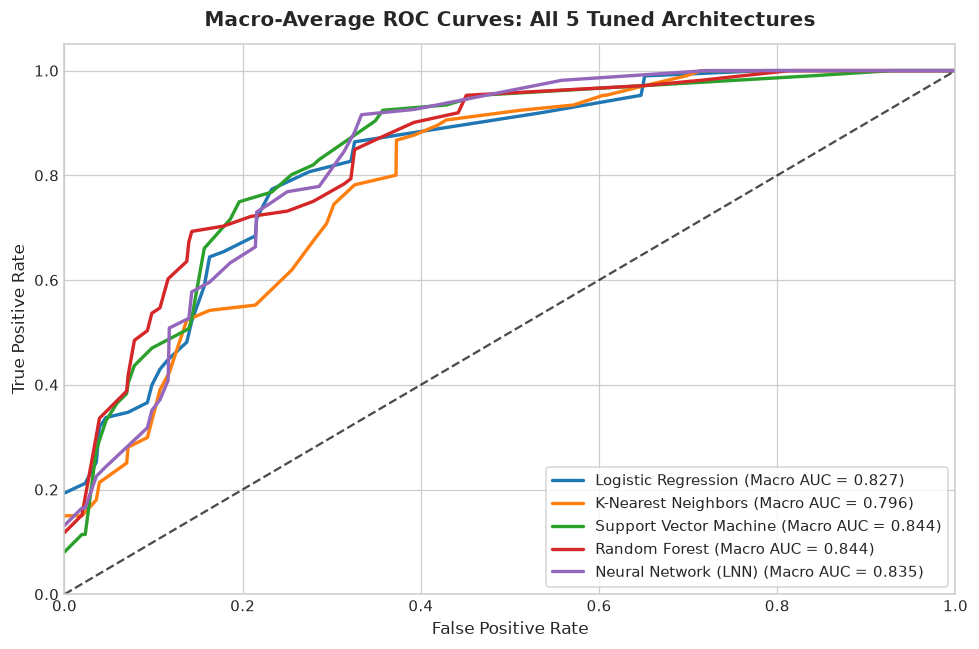

In [10]:
plt.figure(figsize=(9, 6))

for name, prob in tuned_probs.items():
    all_fpr = np.unique(np.concatenate([roc_curve(y_test_bin[:, i], prob[:, i])[0] for i in range(len(classes_list))]))
    mean_tpr = np.zeros_like(all_fpr)
    for i in range(len(classes_list)):
        fpr_i, tpr_i, _ = roc_curve(y_test_bin[:, i], prob[:, i])
        mean_tpr += np.interp(all_fpr, fpr_i, tpr_i)
    mean_tpr /= len(classes_list)
    macro_auc = auc(all_fpr, mean_tpr)
    plt.plot(all_fpr, mean_tpr, lw=2.2, label=f'{name} (Macro AUC = {macro_auc:.3f})')

plt.plot([0, 1], [0, 1], 'k--', lw=1.5, alpha=0.7)
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate', fontsize=11)
plt.ylabel('True Positive Rate', fontsize=11)
plt.title('Macro-Average ROC Curves: All 5 Tuned Architectures', fontsize=13, fontweight='bold', pad=12)
plt.legend(loc='lower right', frameon=True, fontsize=10)
plt.tight_layout()
plt.show()

### 7. Clinical Synthesis & Architecture Champion
- **Hyperparameter Tuning Impact**: Grid search optimization identified parameters that balance bias-variance trade-offs across all 5 candidate families.
- **KNN Integration**: KNN provides an intuitive instance-based baseline; its performance is driven by distance weighting (`weights='distance'`) and neighborhood radius $k$.
- **Champion Architecture**: Identified based on the highest test accuracy, sensitivity, and calibrated ROC-AUC on the holdout clinical cohort.